In [6]:
import pandas as pd
import numpy as np

df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [7]:
print(np.shape(df))
print(df.dtypes)

(5000, 9)
lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object


In [8]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [9]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
df[categorical].nunique()

lead_source          5
industry             6
employment_status    4
location             5
dtype: int64

In [10]:
for col in df[categorical]:
    print(col)
    print(df[col].unique()[:9])
    print('-------------')

lead_source
<StringArray>
['organic_search', 'social_media', 'referral', 'paid_ads', nan, 'events']
Length: 6, dtype: str
-------------
industry
<StringArray>
[   'technology',        'retail', 'manufacturing',     'education',
    'healthcare',             nan,       'finance']
Length: 7, dtype: str
-------------
employment_status
<StringArray>
['employed', 'student', nan, 'unemployed', 'self_employed']
Length: 5, dtype: str
-------------
location
<StringArray>
['europe', 'south_america', nan, 'north_america', 'africa', 'asia']
Length: 6, dtype: str
-------------


In [11]:
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)
df.isna().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [12]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
print (np.shape(df_full_train))
print (np.shape(df_train))
print (np.shape(df_test))
print (np.shape(df_val))

(4000, 9)
(3000, 9)
(1000, 9)
(1000, 9)


In [13]:
y_train = df_train.converted.values
y_test = df_test.converted.values
y_val = df_val.converted.values
print (np.shape(y_train))
print (np.shape(y_test))
print (np.shape(y_val))

(3000,)
(1000,)
(1000,)


In [14]:
df_train = df_train.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)

In [15]:
del df_train['converted']
del df_test['converted']
del df_val['converted']
print (np.shape(df_train))
print (np.shape(df_test))
print (np.shape(df_val))

(3000, 8)
(1000, 8)
(1000, 8)


In [16]:
# Question 1: ROC AUC feature importance; use df_train


In [17]:
from sklearn.metrics import roc_auc_score

numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
for var in numerical:
    auc = round(roc_auc_score(y_train, df_train[var]),3)
    if auc < 0.5:
        auc = round(roc_auc_score(y_train, -df_train[var]),3)
        print ('numerical variable is: ', var, '; AUC is (NEGATIVE): ', auc)
    else:
        print ('numerical variable is: ', var, '; AUC is: ', auc)


numerical variable is:  annual_income ; AUC is:  0.608
numerical variable is:  number_of_courses_viewed ; AUC is:  0.723
numerical variable is:  interaction_count ; AUC is:  0.765
numerical variable is:  lead_score ; AUC is:  0.788


In [18]:
#Question 2: Training the model

In [19]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
dicts_train = df_train[categorical + numerical].to_dict(orient='records')
dicts_val = df_val[numerical + categorical].to_dict(orient='records')

#fit DictVectorizer
dv = DictVectorizer(sparse=False)
x_train = dv.fit_transform(dicts_train)
x_val = dv.transform(dicts_val)

#train logistic model
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(x_train, y_train)

#calcualte AUC
y_pred = model.predict_proba(x_val)[:, 1]
auc = round(roc_auc_score(y_val,y_pred), 3)
print('AUC on Validation dataset is: ', auc)


AUC on Validation dataset is:  0.732


In [20]:
#Question 3: Precision and Recall

In [21]:
import numpy as np
import pandas as pd
precision = []
recall = []
scores =[]

threashold = np.linspace (0, 1, 100)
for t in threashold:
    y_pred_binary = (y_pred >= t). astype(int)
    TP = ((y_pred_binary == 1) & (y_val == 1)).sum()
    TN = ((y_pred_binary == 0) & (y_val == 0)).sum()
    FP = ((y_pred_binary == 1) & (y_val == 0)).sum()
    FN = ((y_pred_binary == 0) & (y_val == 1)).sum()
    p = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    r = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    precision.append(p)
    recall.append(r)
    scores.append((t, TP, FP, TN, FN))

columns = ['Threashold', 'TP', 'FP', 'TN', 'FN']
df_scores = pd.DataFrame(scores, columns=columns)
df_scores

,Threashold,TP,FP,TN,FN
0,0.000000,586,414,0,0
1,0.010101,586,414,0,0
2,0.020202,586,414,0,0
3,0.030303,586,414,0,0
4,0.040404,586,414,0,0
...,...,...,...,...,...
95,0.959596,1,0,414,585
96,0.969697,0,0,414,586
97,0.979798,0,0,414,586
98,0.989899,0,0,414,586


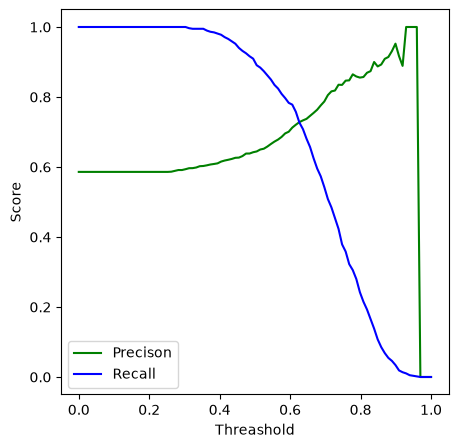

In [22]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(5,5))
plt.plot(threashold, precision, label='Precison', color="green")
plt.plot(threashold, recall, label='Recall', color="blue")
plt.xlabel('Threashold')
plt.ylabel('Score')
plt.legend()
plt.show()

In [23]:
#Question 4: F1 score

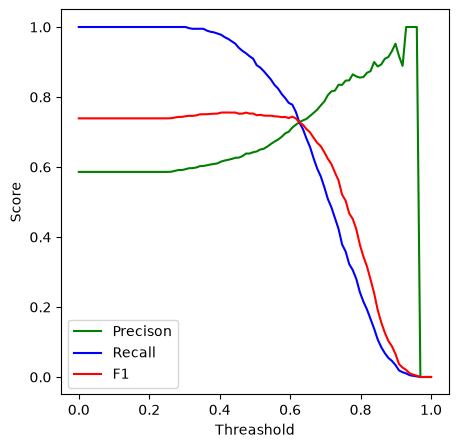

In [24]:
import numpy as np
import pandas as pd
precision = []
recall = []
scores =[]
f1_score = []

threashold = np.linspace (0, 1, 100)
for t in threashold:
    y_pred_binary = (y_pred >= t). astype(int)
    TP = ((y_pred_binary == 1) & (y_val == 1)).sum()
    TN = ((y_pred_binary == 0) & (y_val == 0)).sum()
    FP = ((y_pred_binary == 1) & (y_val == 0)).sum()
    FN = ((y_pred_binary == 0) & (y_val == 1)).sum()
    p = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    r = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    f1 = 2 * ((p * r)/(p + r)) if (p + r) > 0 else 0.0 
    
    precision.append(p)
    recall.append(r)
    f1_score.append(f1)
    scores.append((t, TP, FP, TN, FN, p, r, f1))

columns = ['Threashold', 'TP', 'FP', 'TN', 'FN', 'precision', 'recall' , 'f1']
df_scores = pd.DataFrame(scores, columns=columns)
df_scores
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(5,5))
plt.plot(threashold, precision, label='Precison', color="green")
plt.plot(threashold, recall, label='Recall', color="blue")
plt.plot(threashold, f1_score, label='F1', color='red')
plt.xlabel('Threashold')
plt.ylabel('Score')
plt.legend()
plt.show()

In [25]:
#Question 5: 5-Fold CV
#kfold replaces the manual df_train/df_val split. So you go back to df_full_train and let KFold carve out the validation portion itself — 5 times, each time with a different 20% held out.

In [26]:
from sklearn.model_selection import KFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

auc_q5 = []

for fold,(train_idx, val_idx) in enumerate(kfold.split(df_full_train)): 
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]
    y_train = df_train['converted'].values
    y_val = df_val['converted'].values
    df_train = df_train.drop(columns=['converted'])
    df_val = df_val.drop(columns=['converted'])
    
    dv = DictVectorizer(sparse=False)
    x_train = dv.fit_transform(df_train.to_dict(orient='records'))
    x_val   = dv.transform(df_val.to_dict(orient='records'))
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(x_train,y_train)

    y_pred = model.predict_proba(x_val)[:,1]
    auc = roc_auc_score(y_val, y_pred)
    auc_q5.append(auc)
    print(f'Fold {fold+1}; AUC: {auc:.4f}')
print("---------------------")
print(np.std(auc_q5))


Fold 1; AUC: 0.7306
Fold 2; AUC: 0.7296
Fold 3; AUC: 0.7363
Fold 4; AUC: 0.7412
Fold 5; AUC: 0.7209
---------------------
0.006853233151022138


In [27]:
#Question 6: Hyperparameter Tuning


In [30]:
from sklearn.model_selection import KFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
np.set_printoptions(suppress=True)

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

for C in [0.000001, 0.001, 1]:
    auc = []
    for fold, (train_idx, val_idx) in enumerate (kfold.split(df_full_train)):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train['converted'].values
        y_val = df_val['converted'].values
        df_train = df_train.drop(columns=['converted'])
        df_val = df_val.drop(columns=['converted'])

        dv = DictVectorizer(sparse=False)
        x_train = dv.fit_transform(df_train.to_dict(orient='records'))
        x_val = dv.transform(df_val.to_dict(orient='records'))

        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(x_train,y_train)
        y_pred = model.predict_proba(x_val)[:,1]
        auc.append(roc_auc_score(y_val, y_pred))
    print(f'C={C} | Mean ROC AUC: {np.mean(auc):.3f} | Standard deviation of ROC AUC: {np.std(auc):.3f}')



C=1e-06 | Mean ROC AUC: 0.617 | Standard deviation of ROC AUC: 0.019
C=0.001 | Mean ROC AUC: 0.749 | Standard deviation of ROC AUC: 0.010
C=1 | Mean ROC AUC: 0.732 | Standard deviation of ROC AUC: 0.007
